In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q rarfile
!apt-get install -y -qq unrar

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from google.colab import drive
from sklearn.model_selection import train_test_split
from PIL import Image

drive.mount('/content/drive')

print("Libraries imported successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Libraries imported successfully!


In [ ]:
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
import os

PROJECT_DIR = "/content/drive/MyDrive/UIEB_Project"

print("Folder exists:", os.path.exists(PROJECT_DIR))

if os.path.exists(PROJECT_DIR):
    print("\nFiles inside UIEB_Project:")

    for file in os.listdir(PROJECT_DIR):
        print(file)

Folder exists: True

Files inside UIEB_Project:
uieb_unet_256.keras
reference-890
raw-890 (1)
UIEB_Dataset


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/UIEB_Project"

RAW_EXTRACT = os.path.join(PROJECT_DIR, "raw-890 (1)")
REFERENCE_EXTRACT = os.path.join(PROJECT_DIR, "reference-890")

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Raw folder exists:", os.path.exists(RAW_EXTRACT))
print("Reference folder exists:", os.path.exists(REFERENCE_EXTRACT))

Project folder exists: True
Raw folder exists: True
Reference folder exists: True


In [ ]:
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

raw_images = [
    str(p) for p in Path(RAW_EXTRACT).rglob("*")
    if p.suffix.lower() in extensions
]

reference_images = [
    str(p) for p in Path(REFERENCE_EXTRACT).rglob("*")
    if p.suffix.lower() in extensions
]

print("Total raw images:", len(raw_images))
print("Total reference images:", len(reference_images))

Total raw images: 890
Total reference images: 890


In [ ]:
raw_dictionary = {
    Path(path).stem.lower(): path
    for path in raw_images
}

reference_dictionary = {
    Path(path).stem.lower(): path
    for path in reference_images
}

common_names = sorted(
    set(raw_dictionary.keys()) &
    set(reference_dictionary.keys())
)

paired_raw_images = [
    raw_dictionary[name] for name in common_names
]

paired_reference_images = [
    reference_dictionary[name] for name in common_names
]

print("Matched image pairs:", len(common_names))

assert len(common_names) > 0, "No matching image pairs found!"

assert len(common_names) == len(paired_raw_images)
assert len(common_names) == len(paired_reference_images)

Matched image pairs: 890


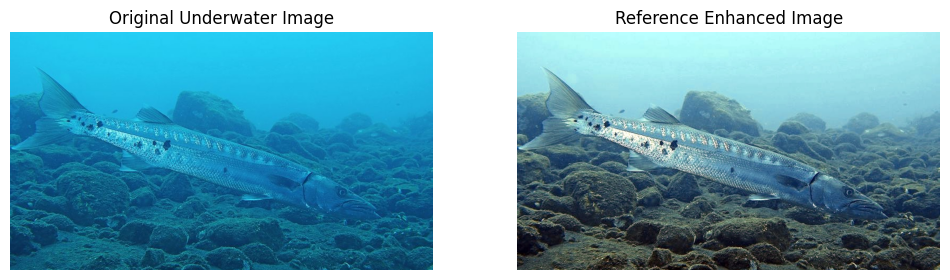

In [ ]:
index = 0

raw_img = Image.open(
    paired_raw_images[index]
).convert("RGB")

reference_img = Image.open(
    paired_reference_images[index]
).convert("RGB")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(raw_img)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(reference_img)
plt.title("Reference Enhanced Image")
plt.axis("off")

plt.show()

In [ ]:
raw_train, raw_temp, ref_train, ref_temp = train_test_split(
    paired_raw_images,
    paired_reference_images,
    test_size=0.20,
    random_state=42
)

raw_val, raw_test, ref_val, ref_test = train_test_split(
    raw_temp,
    ref_temp,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(raw_train))
print("Validation images:", len(raw_val))
print("Testing images:", len(raw_test))

Training images: 712
Validation images: 89
Testing images: 89


In [ ]:
IMG_SIZE = 256
BATCH_SIZE = 4

def load_image(raw_path, reference_path):

    raw_image = tf.io.read_file(raw_path)
    raw_image = tf.io.decode_image(
        raw_image,
        channels=3,
        expand_animations=False
    )
    raw_image.set_shape([None, None, 3])

    reference_image = tf.io.read_file(reference_path)
    reference_image = tf.io.decode_image(
        reference_image,
        channels=3,
        expand_animations=False
    )
    reference_image.set_shape([None, None, 3])

    raw_image = tf.image.resize(
        raw_image,
        [IMG_SIZE, IMG_SIZE]
    )

    reference_image = tf.image.resize(
        reference_image,
        [IMG_SIZE, IMG_SIZE]
    )

    raw_image = tf.cast(raw_image, tf.float32) / 255.0
    reference_image = tf.cast(reference_image, tf.float32) / 255.0

    return raw_image, reference_image

In [ ]:
def augment_image(raw_image, reference_image):

    flip = tf.random.uniform(()) > 0.5

    raw_image = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(raw_image),
        lambda: raw_image
    )

    reference_image = tf.cond(
        flip,
        lambda: tf.image.flip_left_right(reference_image),
        lambda: reference_image
    )

    return raw_image, reference_image

In [ ]:
def create_dataset(raw_paths, reference_paths, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (raw_paths, reference_paths)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(raw_paths),
            seed=42
        )

        dataset = dataset.map(
            augment_image,
            num_parallel_calls=tf.data.AUTOTUNE
        )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_dataset = create_dataset(
    raw_train, ref_train, training=True
)

validation_dataset = create_dataset(
    raw_val, ref_val
)

test_dataset = create_dataset(
    raw_test, ref_test
)

print("Training, validation and testing datasets created!")

Training, validation and testing datasets created!


In [ ]:
def conv_block(inputs, num_filters):
    # Standard double convolutional block for U-Net
    x = tf.keras.layers.Conv2D(num_filters, 3, padding="same", kernel_initializer="he_normal")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = tf.keras.layers.Conv2D(num_filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x

def build_unet():

    inputs = tf.keras.layers.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    # ENCODER

    c1 = conv_block(inputs, 32)
    p1 = tf.keras.layers.MaxPooling2D((2, 2))(c1)

    c2 = conv_block(p1, 64)
    p2 = tf.keras.layers.MaxPooling2D((2, 2))(c2)

    c3 = conv_block(p2, 128)
    p3 = tf.keras.layers.MaxPooling2D((2, 2))(c3)

    c4 = conv_block(p3, 256)
    p4 = tf.keras.layers.MaxPooling2D((2, 2))(c4)

    # BOTTLENECK

    b = conv_block(p4, 512)

    # DECODER

    u4 = tf.keras.layers.Conv2DTranspose(
        256, 2, strides=2, padding="same"
    )(b)

    u4 = tf.keras.layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = tf.keras.layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(c5)

    u3 = tf.keras.layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = tf.keras.layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c6)

    u2 = tf.keras.layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = tf.keras.layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c7)

    u1 = tf.keras.layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    # OUTPUT

    outputs = tf.keras.layers.Conv2D(
        3,
        1,
        activation="sigmoid"
    )(c8)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="UIEB_UNet"
    )

    return model


model = build_unet()

model.summary()

Model: "UIEB_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,771,939 (29.65 MB)

 Trainable params: 7,766,051 (29.63 MB)

 Non-trainable params: 5,888 (23.00 KB)

In [ ]:
def combined_loss(y_true, y_pred):

    mae = tf.reduce_mean(
        tf.abs(y_true - y_pred)
    )

    ssim = tf.reduce_mean(
        tf.image.ssim(
            y_true,
            y_pred,
            max_val=1.0
        )
    )

    return mae + 0.2 * (1.0 - ssim)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss=combined_loss,

    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae")
    ]
)

print("U-Net model compiled successfully!")

U-Net model compiled successfully!


In [ ]:
MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "best_uieb_unet.keras"
)

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

In [ ]:
EPOCHS = 50

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - loss: 0.2973 - mae: 0.1736
Epoch 1: val_loss improved from None to 0.23058, saving model to /content/drive/MyDrive/UIEB_Project/best_uieb_unet.keras

Epoch 1: finished saving model to /content/drive/MyDrive/UIEB_Project/best_uieb_unet.keras
178/178 ━━━━━━━━━━━━━━━━━━━━ 165s 409ms/step - loss: 0.2407 - mae: 0.1467 - val_loss: 0.2306 - val_mae: 0.1460 - learning_rate: 1.0000e-04
Epoch 2/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 0.1661 - mae: 0.1108
Epoch 2: val_loss improved from 0.23058 to 0.16980, saving model to /content/drive/MyDrive/UIEB_Project/best_uieb_unet.keras

Epoch 2: finished saving model to /content/drive/MyDrive/UIEB_Project/best_uieb_unet.keras
178/178 ━━━━━━━━━━━━━━━━━━━━ 48s 134ms/step - loss: 0.1606 - mae: 0.1092 - val_loss: 0.1698 - val_mae: 0.1144 - learning_rate: 1.0000e-04
Epoch 3/50
178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step - loss: 0.1466 - mae: 0.1033
Epoch 3: val_loss improved from 0.16980 to 0.

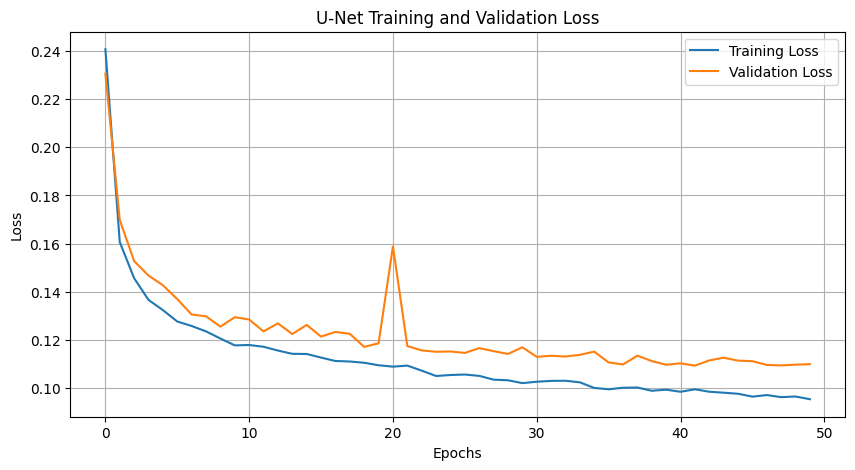

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("U-Net Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
best_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={
        "combined_loss": combined_loss
    },
    compile=False
)

print("Best model loaded successfully!")

Best model loaded successfully!


In [ ]:
psnr_values = []
ssim_values = []

for raw_batch, reference_batch in test_dataset:

    predictions = best_model.predict(
        raw_batch,
        verbose=0
    )

    batch_psnr = tf.image.psnr(
        reference_batch,
        predictions,
        max_val=1.0
    )

    batch_ssim = tf.image.ssim(
        reference_batch,
        predictions,
        max_val=1.0
    )

    psnr_values.extend(batch_psnr.numpy())
    ssim_values.extend(batch_ssim.numpy())


print("Average Test PSNR:", np.mean(psnr_values))
print("Average Test SSIM:", np.mean(ssim_values))

Average Test PSNR: 20.512821
Average Test SSIM: 0.8656167


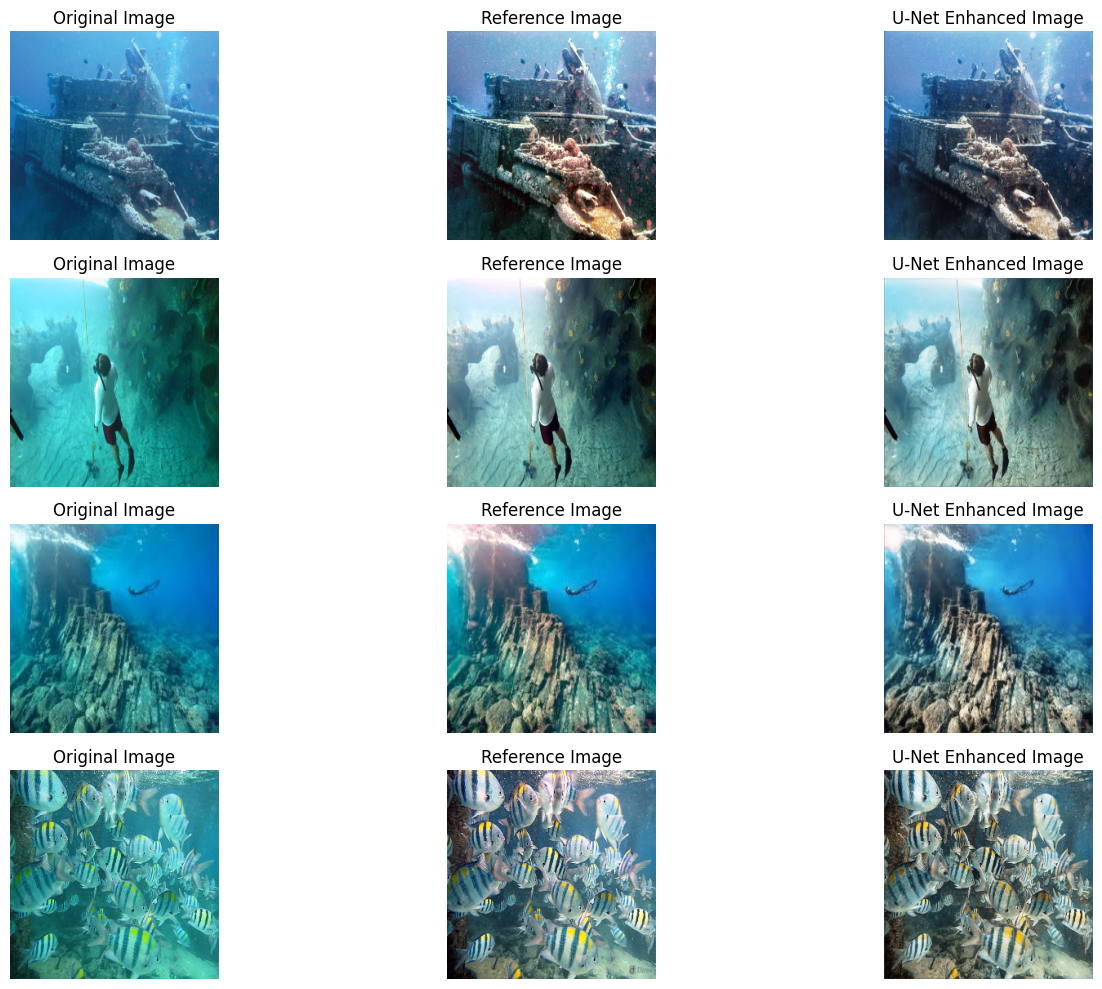

In [ ]:
for raw_batch, reference_batch in test_dataset.take(1):

    predictions = best_model.predict(
        raw_batch,
        verbose=0
    )

    plt.figure(figsize=(15, 10))

    for i in range(min(4, len(raw_batch))):

        plt.subplot(4, 3, i * 3 + 1)
        plt.imshow(raw_batch[i].numpy())
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(4, 3, i * 3 + 2)
        plt.imshow(reference_batch[i].numpy())
        plt.title("Reference Image")
        plt.axis("off")

        plt.subplot(4, 3, i * 3 + 3)
        plt.imshow(np.clip(predictions[i], 0, 1))
        plt.title("U-Net Enhanced Image")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
best_model.save(MODEL_PATH)

print("Model saved successfully!")
print("Saved model path:", MODEL_PATH)

Model saved successfully!
Saved model path: /content/drive/MyDrive/UIEB_Project/best_uieb_unet.keras


In [ ]:
from google.colab import files

files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>